In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

students= pd.read_csv("students_100.csv")
students.head()

,student_id,city,study_hours,phone_hours,height_cm,maths,english,science
0,1,Lahore,3.0,3.5,177.0,49.0,61.0,54.0
1,2,Islamabad,3.4,2.7,173.0,71.0,59.0,71.0
2,3,Lahore,2.7,4.2,157.0,56.0,66.0,54.0
3,4,Karachi,1.9,7.4,158.0,39.0,55.0,53.0
4,5,Lahore,2.5,2.8,161.0,69.0,65.0,70.0


In [3]:
X= torch.tensor(
    students[["study_hours", "phone_hours",]].values,
    dtype=torch.float32,
)

Y=torch.tensor(
    students[["maths"]].values,
    dtype=torch.float32
)
print("X shape: ", X.shape, "y shape: ", Y.shape)


X shape:  torch.Size([100, 2]) y shape:  torch.Size([100, 1])


In [29]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, 8),
    nn.ReLU(),
    nn.Linear(8, 4),  # New hidden layer
    nn.ReLU(),
    nn.Linear(4, 1),
)

loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.5)

In [30]:
losses =[]
for epoch in range(300):
    guess = model(X)
    loss= loss_fn(guess,Y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if epoch % 50 ==0:
        print(f"epoch {epoch:3} loss= {loss.item():.1f}")

epoch   0 loss= 3116.9
epoch  50 loss= 83.8
epoch 100 loss= 50.1
epoch 150 loss= 48.9
epoch 200 loss= 47.7
epoch 250 loss= 47.0


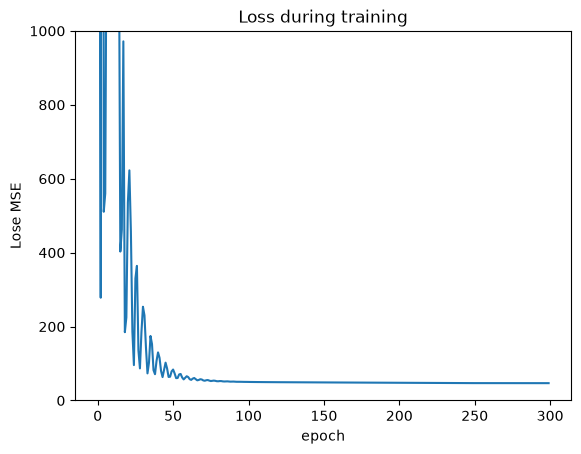

In [18]:
plt.plot(losses)
plt.ylim(0,1000)
plt.title("Loss during training")
plt.xlabel("epoch")
plt.ylabel("Lose MSE")
plt.show()

In [ ]:
with torch.no_grad():
    new_student = torch.tensor([[3,2]], dtype=torch.float32)
    print("3 study hours, 2 phone hourse ->", round(model(new_student).item(),1), " marks")

3 study hours, 2 phone hourse -> 62.3  marks
